In [1]:
import os
import logging
import warnings

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from pathlib import Path

warnings.filterwarnings('ignore')
logging.basicConfig(level=logging.INFO, format="%(asctime)s - %(levelname)s - %(message)s")
logger = logging.getLogger(__name__)
logging.getLogger('matplotlib').setLevel(logging.WARNING)

DATA_DIR = Path(os.environ.get('DATA_DIR', '.'))
FIG_DIR = Path('figures')
FIG_DIR.mkdir(exist_ok=True)

YEARS = [2017, 2018, 2019, 2020, 2021]

# Storytelling with Data palette: grey by default, one highlight (steelblue), one contrast for declines (tomato)
BLUE, RED = 'steelblue', 'tomato'
GREY, LIGHT, DARK, TEXT = '#A6A6A6', '#D9D9D9', '#595959', '#404040'
FIGSIZE = (12, 4.6)

plt.rcParams.update({
    'figure.dpi': 110, 'savefig.dpi': 200, 'font.size': 12, 'text.color': TEXT,
    'axes.titlesize': 14, 'axes.titlelocation': 'left', 'axes.titlecolor': TEXT, 'axes.titlepad': 14,
    'axes.edgecolor': GREY, 'axes.linewidth': 0.8, 'axes.spines.top': False, 'axes.spines.right': False,
    'xtick.color': DARK, 'ytick.color': DARK, 'xtick.labelsize': 11, 'ytick.labelsize': 11,
})


def declutter(ax, hide_y=False, pct_ticks=None):
    ax.tick_params(length=0)
    if hide_y:
        ax.spines['left'].set_visible(False)
        ax.set_yticks([])
    if pct_ticks:
        ax.set_yticks(pct_ticks)
        ax.set_yticklabels([f'{t}%' for t in pct_ticks])


def label_ends(ax, x, labels, min_gap, ha='left'):
    # labels: list of (y, text, colour); pushes labels apart vertically so they never overlap
    ordered = sorted(labels, key=lambda item: item[0])
    positions = [item[0] for item in ordered]
    for i in range(1, len(positions)):
        positions[i] = max(positions[i], positions[i - 1] + min_gap)
    for (_, text, color), position in zip(ordered, positions):
        ax.text(x, position, text, va='center', ha=ha, color=color, fontsize=11)


def line_chart(ax, data, highlights, min_gap, title, pct_ticks):
    # data: DataFrame indexed by series with year columns; highlights: {series: colour}; everything else grey
    labels = []
    for name in data.index:
        values = data.loc[name].dropna()
        color = highlights.get(name, GREY)
        ax.plot(values.index, values.values, color=color, linewidth=2.6 if name in highlights else 1.4)
        ax.scatter([values.index[0], values.index[-1]], [values.iloc[0], values.iloc[-1]], color=color, s=28, zorder=3)
        labels.append((values.iloc[-1], f'{name} {values.iloc[-1]:.0f}%', color if name in highlights else DARK))
        if name in highlights:
            ax.text(values.index[0] - 0.1, values.iloc[0], f'{values.iloc[0]:.0f}%', va='center', ha='right', color=color, fontsize=11)
    label_ends(ax, data.columns[-1] + 0.1, labels, min_gap)
    ax.set_title(title)
    ax.set_xticks(list(data.columns))
    ax.set_xlim(data.columns[0] - 0.4, data.columns[-1] + 0.4)
    ax.set_ylim(0, pct_ticks[-1] * 1.1)
    declutter(ax, pct_ticks=pct_ticks)


def bar_chart(ax, series, title, highlight_last):
    colors = [LIGHT] * len(series)
    if highlight_last:
        colors[-1] = BLUE
    ax.bar(series.index, series.values, color=colors, width=0.65)
    for x, value, color in zip(series.index, series.values, colors):
        ax.text(x, value + 0.8, f'{value:.0f}%', ha='center', color=BLUE if color == BLUE else DARK)
    ax.set_title(title)
    ax.set_xticks(list(series.index))
    ax.set_ylim(0, 35)
    declutter(ax, hide_y=True)


def save_fig(fig, name):
    path = FIG_DIR / f'{name}.png'
    fig.savefig(path, bbox_inches='tight', facecolor='white')
    plt.show()
    logger.info(f'Figure saved to {path}')

In [2]:
raw_df = pd.read_csv(DATA_DIR / 'kaggle_survey_2017_2021.csv', low_memory=False)

questions = raw_df.iloc[0].to_dict()
df = raw_df.iloc[1:].copy()
df['year'] = df['-'].astype(int)
df = df.drop(columns=['-'])

respondents = df['year'].value_counts().sort_index()

logger.info(f'Raw shape: {raw_df.shape} | first row holds the question text')
logger.info(f'Respondents per year:\n{respondents}')
logger.info(f'Growth 2017 to 2021: {respondents[2021] / respondents[2017] - 1:.0%}')
logger.info(f'Columns: {df.shape[1]} | single-choice: {sum('_Part' not in c and 'OTHER' not in c for c in df.columns)} | multi-select parts: {sum('_Part' in c for c in df.columns)}')

df.head()

2026-11-02 14:51:38,179 - INFO - Raw shape: (106302, 293) | first row holds the question text
2026-11-02 14:51:38,179 - INFO - Respondents per year:
year
2017    16716
2018    23859
2019    19717
2020    20036
2021    25973
Name: count, dtype: int64
2026-11-02 14:51:38,181 - INFO - Growth 2017 to 2021: 55%
2026-11-02 14:51:38,182 - INFO - Columns: 293 | single-choice: 22 | multi-select parts: 245


,Time from Start to Finish (seconds),Q1,Q2,Q3,Q4,Q5,Q6,Q7_Part_1,Q7_Part_2,Q7_Part_3,...,Q38_B_Part_2,Q38_B_Part_3,Q38_B_Part_4,Q38_B_Part_5,Q38_B_Part_6,Q38_B_Part_7,Q38_B_Part_9,Q38_B_Part_11,Q38_B_OTHER,year
1,910,50-54,Man,India,Bachelorâ€™s degree,Other,5-10 years,Python,R,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2021
2,784,50-54,Man,Indonesia,Masterâ€™s degree,Program/Project Manager,20+ years,NaN,NaN,SQL,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2021
3,924,22-24,Man,Pakistan,Masterâ€™s degree,Software Engineer,1-3 years,Python,NaN,NaN,...,NaN,NaN,NaN,TensorBoard,NaN,NaN,NaN,NaN,NaN,2021
4,575,45-49,Man,Mexico,Doctoral degree,Research Scientist,20+ years,Python,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2021
5,781,45-49,Man,India,Doctoral degree,Other,< 1 years,Python,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2021


In [3]:
question_groups = {}
for col in df.columns:
    if col.startswith('Q'):
        question_groups.setdefault(col.split('_Part')[0].split('_OTHER')[0], []).append(col)

coverage = pd.DataFrame({
    group: df.groupby('year')[cols].apply(lambda d: d.notna().any(axis=1).mean()) for group, cols in question_groups.items()
}).T.round(2)

logger.info('=== Share of respondents with an answer, by question group and year ===')
logger.info(f'Asked in all five years: {list(coverage[(coverage > 0).all(axis=1)].index)}')
logger.info(f'Asked 2018 onwards only: {list(coverage[(coverage[2017] == 0) & (coverage.drop(columns=2017) > 0).all(axis=1)].index)}')
coverage

2026-11-02 14:51:39,130 - INFO - === Share of respondents with an answer, by question group and year ===
2026-11-02 14:51:39,133 - INFO - Asked in all five years: ['Q1', 'Q2', 'Q3', 'Q4', 'Q5', 'Q6', 'Q8']
2026-11-02 14:51:39,134 - INFO - Asked 2018 onwards only: ['Q7', 'Q9', 'Q10', 'Q14', 'Q15', 'Q16', 'Q23', 'Q24', 'Q25', 'Q27_A', 'Q32_A', 'Q37_A', 'Q40', 'Q42']


year,2017,2018,2019,2020,2021
Q1,0.97,1.00,1.00,1.00,1.00
Q2,0.99,1.00,1.00,1.00,1.00
Q3,0.99,1.00,1.00,1.00,1.00
Q4,0.90,0.98,0.98,0.98,1.00
Q5,0.71,0.96,0.97,0.96,1.00
Q6,0.81,0.78,0.79,0.95,1.00
Q7,0.00,0.77,0.73,0.88,0.95
Q8,0.66,0.78,0.73,0.89,0.96
Q9,0.00,0.78,0.73,0.83,0.85
Q10,0.00,0.47,0.46,0.59,0.67


In [4]:
df['gender'] = df['Q2'].map({'Female': 'Woman', 'Male': 'Man', 'Woman': 'Woman', 'Man': 'Man'}).fillna('Other / not stated')

df['age_group'] = df['Q1'].replace({'18-21': '18-24', '22-24': '18-24', '25-29': '25-34', '30-34': '25-34', '35-39': '35-44', '40-44': '35-44'})
df.loc[df['Q1'].isin(['45-49', '50-54', '55-59', '60-69', '70+']), 'age_group'] = '45+'

df['country'] = df['Q3'].replace({
    'United States of America': 'United States', 'United Kingdom of Great Britain and Northern Ireland': 'United Kingdom',
    "People 's Republic of China": 'China',
})

df['is_student'] = df['Q5'] == 'Student'

df['employer_ml'] = df['Q23'].map({
    'We have well established ML methods (i.e., models in production for more than 2 years)': 'In production > 2 years',
    'We recently started using ML methods (i.e., models in production for less than 2 years)': 'In production < 2 years',
    'We use ML methods for generating insights (but do not put working models into production)': 'Insights only',
    'We are exploring ML methods (and may one day put a model into production)': 'Exploring',
    'No (we do not use ML methods)': 'No ML',
    'I do not know': 'Do not know',
})

logger.info('Gender, age group, country, student flag and employer ML maturity harmonised across years')
logger.info(f'Gender share by year (%):\n{pd.crosstab(df['gender'], df['year'], normalize='columns').mul(100).round(1)}')

2026-11-02 14:51:39,205 - INFO - Gender, age group, country, student flag and employer ML maturity harmonised across years
2026-11-02 14:51:39,219 - INFO - Gender share by year (%):
year                2017  2018  2019  2020  2021
gender                                          
Man                 81.4  81.4  81.8  78.8  79.3
Other / not stated   2.0   1.8   1.9   1.8   1.9
Woman               16.6  16.8  16.3  19.4  18.8


In [5]:
# option labels that Kaggle reworded between years, mapped to one name
OPTION_ALIASES = {
    'Scikit-Learn': 'Scikit-learn', 'Xgboost': 'XGBoost',
    'Transformer Networks (BERT, gpt-2, etc)': 'Transformer Networks', 'Transformer Networks (BERT, gpt-3, etc)': 'Transformer Networks',
    'Gradient Boosting Machines (xgboost, lightgbm, etc)': 'Gradient Boosting Machines', 'Linear or Logistic Regression': 'Linear / Logistic Regression',
    'Kaggle Learn': 'Kaggle Learn Courses', 'Kaggle Courses (i.e. Kaggle Learn)': 'Kaggle Learn Courses',
    'University Courses (resulting in a university degree)': 'University courses',
}


def multi_select_share(prefix, exclude=()):
    # share of respondents who answered the question and ticked each option, by year
    cols = question_groups[prefix]
    rows = {}
    for year, year_df in df.groupby('year'):
        answers = year_df[cols].apply(lambda s: s.dropna().iloc[0].strip() if s.notna().any() else None).replace(OPTION_ALIASES)
        keep = [c for c in cols if answers[c] is not None and answers[c] not in exclude]
        if not keep or not year_df[keep].notna().any(axis=1).any():
            continue
        answered = year_df[keep].notna().any(axis=1)
        shares = year_df.loc[answered, keep].notna().mean() * 100
        shares.index = [answers[c] for c in keep]
        rows[year] = shares.groupby(level=0).max()
    return pd.DataFrame(rows)


def single_choice_share(col):
    return pd.crosstab(df[col], df['year'], normalize='columns') * 100


languages = multi_select_share('Q7')
logger.info(f'Regular-use programming languages, % of respondents who answered (2018 onwards):\n{languages.round(1)}')

2026-11-02 14:51:39,593 - INFO - Regular-use programming languages, % of respondents who answered (2018 onwards):
                       2018  2019  2020  2021
Bash                   14.8  14.2  10.0   9.0
C                       NaN  11.7  18.7  19.1
C++                     NaN  15.8  21.6  22.5
Java                   21.9  15.8  19.0  19.4
Javascript              NaN  15.2  16.9  17.6
Javascript/Typescript  17.8   NaN   NaN   NaN
Julia                   1.3   NaN   1.5   1.2
MATLAB                 14.5  10.6  12.5  11.9
Other                   3.4   8.0  11.0  10.5
Python                 86.0  89.7  87.7  88.8
R                      36.6  32.0  24.2  21.7
SQL                    45.2  45.6  42.6  43.7
Swift                   NaN   NaN   1.1   1.0


2026-11-02 14:51:39,618 - INFO - === Insight 1: the community grew 55% and its centre of gravity moved to India ===
2026-11-02 14:51:39,618 - INFO - Respondents by year: {2017: 16716, 2018: 23859, 2019: 19717, 2020: 20036, 2021: 25973}
2026-11-02 14:51:39,620 - INFO - Country share (%):
year           2017  2018  2019  2020  2021
country                                    
India          16.3  18.5  24.3  29.2  28.6
United States  25.3  19.8  15.6  11.2  10.2
China           2.8   6.9   2.9   2.4   3.1
Brazil          2.8   3.1   3.7   3.5   2.9
Japan           1.7   2.5   3.4   3.2   3.5
Russia          3.5   3.7   3.2   2.9   2.9


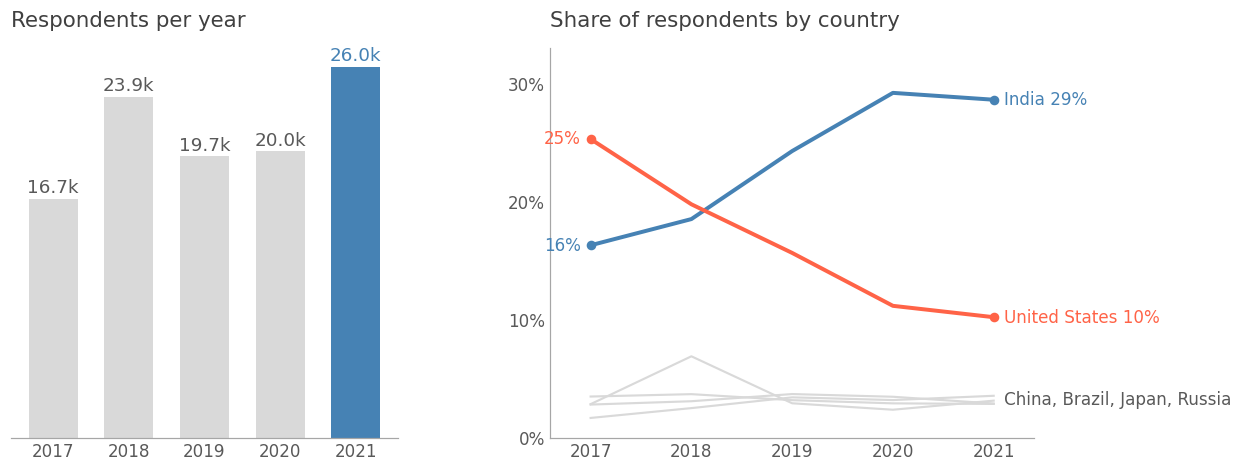

2026-11-02 14:51:39,803 - INFO - Figure saved to figures\01_growth_geography.png


In [6]:
top_countries = ['India', 'United States', 'China', 'Brazil', 'Japan', 'Russia']
country_share = single_choice_share('country').loc[top_countries]

logger.info('=== Insight 1: the community grew 55% and its centre of gravity moved to India ===')
logger.info(f'Respondents by year: {respondents.to_dict()}')
logger.info(f'Country share (%):\n{country_share.round(1)}')

fig, axes = plt.subplots(1, 2, figsize=FIGSIZE, gridspec_kw={'width_ratios': [1, 1.25], 'wspace': 0.35})

bars = axes[0].bar(YEARS, respondents.values, color=[LIGHT] * 4 + [BLUE], width=0.65)
for bar, value in zip(bars, respondents.values):
    axes[0].text(bar.get_x() + bar.get_width() / 2, value + 400, f'{value / 1000:.1f}k', ha='center', color=BLUE if value == respondents.max() else DARK)
axes[0].set_title('Respondents per year')
axes[0].set_xticks(YEARS)
declutter(axes[0], hide_y=True)

for country in top_countries[2:]:
    axes[1].plot(YEARS, country_share.loc[country], color=LIGHT, linewidth=1.4)
line_chart(axes[1], country_share.loc[['India', 'United States']], {'India': BLUE, 'United States': RED}, min_gap=3, title='Share of respondents by country', pct_ticks=[0, 10, 20, 30])
axes[1].text(2021.1, 3.2, 'China, Brazil, Japan, Russia', va='center', color=DARK, fontsize=11)

save_fig(fig, '01_growth_geography')

2026-11-02 14:51:39,831 - INFO - === Insight 2: the community is getting younger and more student-heavy, but not more gender-balanced ===
2026-11-02 14:51:39,833 - INFO - Age group share (%):
year       2017  2018  2019  2020  2021
age_group                              
18-24      22.6  34.3  31.0  36.2  36.9
25-34      44.2  41.6  38.4  34.0  32.2
35-44      20.1  15.1  17.9  16.9  16.9
45+        13.1   8.9  12.7  12.8  13.9
2026-11-02 14:51:39,833 - INFO - Student share (%), 2017 had no Student option: {2018: 22.0, 2019: 20.4, 2020: 25.8, 2021: 26.2}
2026-11-02 14:51:39,834 - INFO - Women share (%): {2017: 16.6, 2018: 16.8, 2019: 16.3, 2020: 19.4, 2021: 18.8}


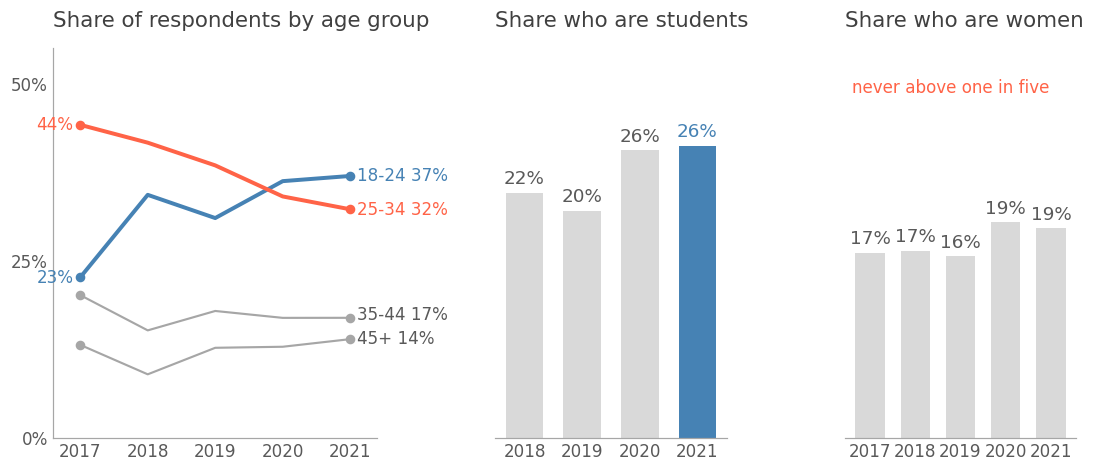

2026-11-02 14:51:40,014 - INFO - Figure saved to figures\02_demographics.png


In [7]:
age_share = single_choice_share('age_group').loc[['18-24', '25-34', '35-44', '45+']]
student_share = df.groupby('year')['is_student'].mean().mul(100).drop(2017)
women_share = (df['gender'] == 'Woman').groupby(df['year']).mean() * 100

logger.info('=== Insight 2: the community is getting younger and more student-heavy, but not more gender-balanced ===')
logger.info(f'Age group share (%):\n{age_share.round(1)}')
logger.info(f'Student share (%), 2017 had no Student option: {student_share.round(1).to_dict()}')
logger.info(f'Women share (%): {women_share.round(1).to_dict()}')

fig, axes = plt.subplots(1, 3, figsize=FIGSIZE, gridspec_kw={'width_ratios': [1.4, 1, 1], 'wspace': 0.45})
line_chart(axes[0], age_share, {'18-24': BLUE, '25-34': RED}, min_gap=3.5, title='Share of respondents by age group', pct_ticks=[0, 25, 50])
bar_chart(axes[1], student_share, 'Share who are students', highlight_last=True)
bar_chart(axes[2], women_share, 'Share who are women', highlight_last=False)
axes[2].text(2016.6, 31, 'never above one in five', color=RED, fontsize=11)

save_fig(fig, '02_demographics')

2026-11-02 14:51:40,034 - INFO - === Insight 3: Python is the default; R keeps losing ground, SQL holds steady ===
2026-11-02 14:51:40,036 - INFO - Regular use (%):
        2018  2019  2020  2021
Python  86.0  89.7  87.7  88.8
SQL     45.2  45.6  42.6  43.7
R       36.6  32.0  24.2  21.7
2026-11-02 14:51:40,037 - INFO - Recommended first language (%):
year    2017  2018  2019  2020  2021
Q8                                  
Python  63.1  76.0  79.1  80.3  81.4
SQL      3.5   4.9   5.7   4.8   5.4
R       24.0  12.6   9.4   7.1   5.8


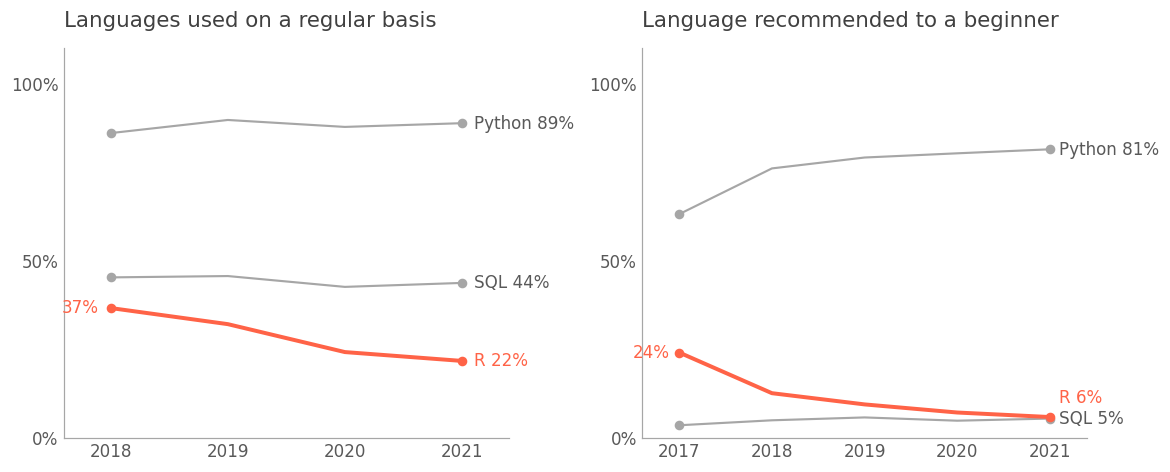

2026-11-02 14:51:40,205 - INFO - Figure saved to figures\03_python_vs_r.png


In [8]:
recommended = single_choice_share('Q8')

logger.info('=== Insight 3: Python is the default; R keeps losing ground, SQL holds steady ===')
logger.info(f'Regular use (%):\n{languages.loc[['Python', 'SQL', 'R']].round(1)}')
logger.info(f'Recommended first language (%):\n{recommended.loc[['Python', 'SQL', 'R']].round(1)}')

fig, axes = plt.subplots(1, 2, figsize=FIGSIZE, gridspec_kw={'wspace': 0.3})
line_chart(axes[0], languages.loc[['Python', 'SQL', 'R']], {'R': RED}, min_gap=6, title='Languages used on a regular basis', pct_ticks=[0, 50, 100])
line_chart(axes[1], recommended.loc[['Python', 'SQL', 'R']], {'R': RED}, min_gap=6, title='Language recommended to a beginner', pct_ticks=[0, 50, 100])

save_fig(fig, '03_python_vs_r')

2026-11-02 14:51:40,589 - INFO - === Insight 4: PyTorch is the only major framework still growing; TensorFlow and Keras are slipping ===
2026-11-02 14:51:40,591 - INFO - Framework regular use (%):
              2018  2019  2020  2021
Scikit-learn  79.6  79.5  79.3  79.2
TensorFlow    64.9  49.3  53.6  53.1
Keras         52.9  48.7  47.9  45.2
PyTorch       24.9  28.9  32.4  34.5
XGBoost       36.2  35.9  30.4  33.8
2026-11-02 14:51:40,592 - INFO - PyTorch to TensorFlow ratio: 2018 0.38 | 2021 0.65


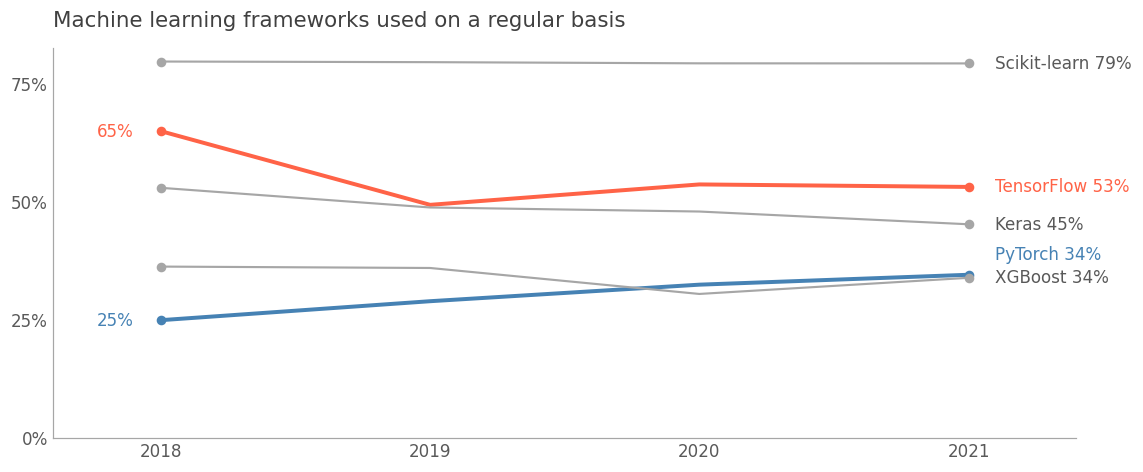

2026-11-02 14:51:40,711 - INFO - Figure saved to figures\04_frameworks.png


In [9]:
frameworks = multi_select_share('Q16').loc[['Scikit-learn', 'TensorFlow', 'Keras', 'PyTorch', 'XGBoost']]

logger.info('=== Insight 4: PyTorch is the only major framework still growing; TensorFlow and Keras are slipping ===')
logger.info(f'Framework regular use (%):\n{frameworks.round(1)}')
logger.info(f'PyTorch to TensorFlow ratio: 2018 {frameworks.loc['PyTorch', 2018] / frameworks.loc['TensorFlow', 2018]:.2f} | 2021 {frameworks.loc['PyTorch', 2021] / frameworks.loc['TensorFlow', 2021]:.2f}')

fig, ax = plt.subplots(figsize=FIGSIZE)
line_chart(ax, frameworks, {'PyTorch': BLUE, 'TensorFlow': RED}, min_gap=5, title='Machine learning frameworks used on a regular basis', pct_ticks=[0, 25, 50, 75])

save_fig(fig, '04_frameworks')

2026-11-02 14:51:41,044 - INFO - === Insight 5: everyday ML is still regression and trees; transformers are the only method gaining share ===
2026-11-02 14:51:41,046 - INFO - Algorithm regular use (%):
                                   2019  2020  2021
Evolutionary Approaches             6.7   5.6   5.4
Generative Adversarial Networks     7.6   7.8   7.6
Transformer Networks                7.0   9.9  12.7
Recurrent Neural Networks          26.3  26.3  23.7
Bayesian Approaches                28.9  27.7  24.6
Dense Neural Networks (MLPs, etc)  25.8  25.6  25.0
Convolutional Neural Networks      42.2  44.5  41.5
Gradient Boosting Machines         42.9  39.0  42.4
Decision Trees or Random Forests   65.8  66.9  66.5
Linear / Logistic Regression       79.2  80.2  77.6
2026-11-02 14:51:41,046 - INFO - Change 2019 to 2021 (pp):
Bayesian Approaches                 -4.3
Recurrent Neural Networks           -2.6
Linear / Logistic Regression        -1.6
Evolutionary Approaches             -1.3
Con

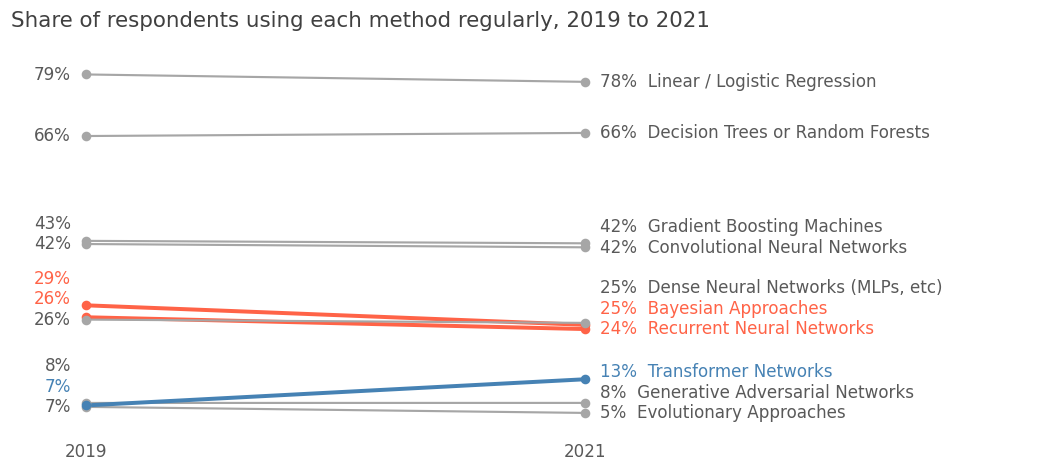

2026-11-02 14:51:41,210 - INFO - Figure saved to figures\05_algorithms.png


In [10]:
algorithms = multi_select_share('Q17').drop(index='Other').sort_values(2021)
algorithms_change = algorithms[2021] - algorithms[2019]

logger.info('=== Insight 5: everyday ML is still regression and trees; transformers are the only method gaining share ===')
logger.info(f'Algorithm regular use (%):\n{algorithms.round(1)}')
logger.info(f'Change 2019 to 2021 (pp):\n{algorithms_change.round(1).sort_values()}')

# slopegraph: 2019 on the left, 2021 on the right; blue up more than 2 points, red down more than 2 points, grey otherwise
fig, ax = plt.subplots(figsize=FIGSIZE)
left_labels, right_labels = [], []
for name, change in algorithms_change.items():
    color = BLUE if change > 2 else (RED if change < -2 else GREY)
    text_color = color if color != GREY else DARK
    ax.plot([0, 1], algorithms.loc[name, [2019, 2021]], color=color, linewidth=2.6 if color != GREY else 1.4)
    ax.scatter([0, 1], algorithms.loc[name, [2019, 2021]], color=color, s=28, zorder=3)
    left_labels.append((algorithms.loc[name, 2019], f'{algorithms.loc[name, 2019]:.0f}%', text_color))
    right_labels.append((algorithms.loc[name, 2021], f'{algorithms.loc[name, 2021]:.0f}%  {name}', text_color))
label_ends(ax, -0.03, left_labels, min_gap=4.5, ha='right')
label_ends(ax, 1.03, right_labels, min_gap=4.5)
ax.set_title('Share of respondents using each method regularly, 2019 to 2021')
ax.set_xticks([0, 1], ['2019', '2021'])
ax.set_xlim(-0.15, 1.9)
ax.set_ylim(0, 85)
ax.spines['bottom'].set_visible(False)
declutter(ax, hide_y=True)

save_fig(fig, '05_algorithms')

2026-11-02 14:51:41,575 - INFO - === Insight 6: among cloud users AWS still leads, but Azure is closing the gap ===
2026-11-02 14:51:41,576 - INFO - Base: respondents naming at least one provider. Share of all respondents answering the cloud question (%): {2018: 79.1, 2019: 24.8, 2020: 25.2, 2021: 27.1}
2026-11-02 14:51:41,577 - INFO - Cloud platform regular use among cloud users (%):
       2018  2019  2020  2021
AWS    66.4  57.7  57.2  54.6
GCP    42.6  44.6  46.6  46.1
Azure  33.9  28.3  34.8  36.0
2026-11-02 14:51:41,578 - INFO - Note: 2018 asked everyone and had a none option; from 2019 the question was routed to a smaller group, so compare ranking and gap, not levels


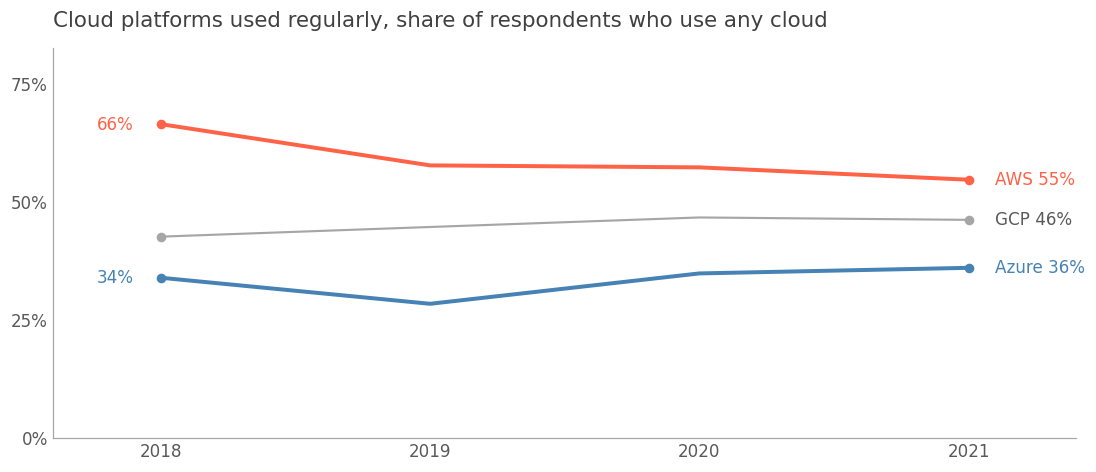

2026-11-02 14:51:41,682 - INFO - Figure saved to figures\06_cloud.png


In [11]:
cloud = multi_select_share('Q27_A', exclude=('I have not used any cloud providers', 'Other'))
big_three = cloud.loc[['Amazon Web Services (AWS)', 'Google Cloud Platform (GCP)', 'Microsoft Azure']]
big_three.index = ['AWS', 'GCP', 'Azure']
cloud_answered = df[question_groups['Q27_A']].notna().any(axis=1).groupby(df['year']).mean().mul(100).drop(2017)

logger.info('=== Insight 6: among cloud users AWS still leads, but Azure is closing the gap ===')
logger.info(f'Base: respondents naming at least one provider. Share of all respondents answering the cloud question (%): {cloud_answered.round(1).to_dict()}')
logger.info(f'Cloud platform regular use among cloud users (%):\n{big_three.round(1)}')
logger.info('Note: 2018 asked everyone and had a none option; from 2019 the question was routed to a smaller group, so compare ranking and gap, not levels')

fig, ax = plt.subplots(figsize=FIGSIZE)
line_chart(ax, big_three, {'Azure': BLUE, 'AWS': RED}, min_gap=5, title='Cloud platforms used regularly, share of respondents who use any cloud', pct_ticks=[0, 25, 50, 75])

save_fig(fig, '06_cloud')

2026-11-02 14:51:41,706 - INFO - === Insight 7: only about a third of employers have ML in production, and that share has not grown since 2018 ===
2026-11-02 14:51:41,708 - INFO - Employer ML maturity (% of respondents who answered):
year                     2018  2019  2020  2021
employer_ml                                    
In production > 2 years  13.5  19.1  17.2  16.5
In production < 2 years  18.3  20.6  16.2  14.1
Insights only            10.2  11.7  11.2  10.7
Exploring                22.7  21.3  21.1  21.3
No ML                    21.3  18.3  20.0  20.5
Do not know              14.0   9.0  14.3  17.0
2026-11-02 14:51:41,708 - INFO - Models in production (either band) (%): {2018: 31.8, 2019: 39.8, 2020: 33.4, 2021: 30.6}


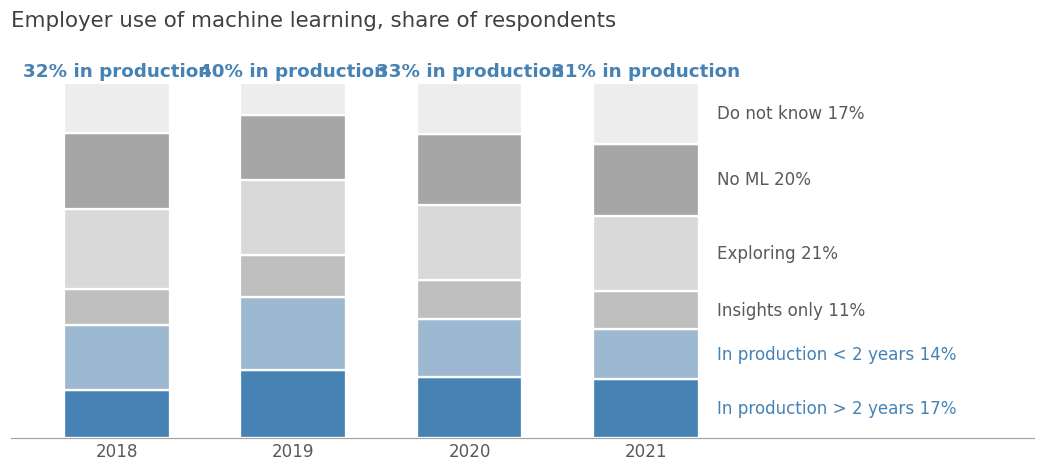

2026-11-02 14:51:41,833 - INFO - Figure saved to figures\07_employer_ml_maturity.png


In [12]:
maturity_order = ['In production > 2 years', 'In production < 2 years', 'Insights only', 'Exploring', 'No ML', 'Do not know']
maturity_colors = [BLUE, '#9DB9D1', '#BFBFBF', '#D9D9D9', '#A6A6A6', '#EDEDED']
maturity = single_choice_share('employer_ml').loc[maturity_order]
in_production = maturity.iloc[:2].sum()

logger.info('=== Insight 7: only about a third of employers have ML in production, and that share has not grown since 2018 ===')
logger.info(f'Employer ML maturity (% of respondents who answered):\n{maturity.round(1)}')
logger.info(f'Models in production (either band) (%): {in_production.round(1).to_dict()}')

# 100% stacked bars: production bands in blue, the rest in greys, labels beside the last bar instead of a legend
fig, ax = plt.subplots(figsize=FIGSIZE)
years = list(maturity.columns)
bottom = np.zeros(len(years))
labels = []
for level, color in zip(maturity_order, maturity_colors):
    values = maturity.loc[level].values
    ax.bar(years, values, bottom=bottom, color=color, width=0.6, edgecolor='white', linewidth=1.5)
    labels.append((bottom[-1] + values[-1] / 2, f'{level} {values[-1]:.0f}%', BLUE if level.startswith('In production') else DARK))
    bottom += values
for x, value in zip(years, in_production.values):
    ax.text(x, 102, f'{value:.0f}% in production', ha='center', color=BLUE, fontweight='bold')
label_ends(ax, years[-1] + 0.4, labels, min_gap=8)
ax.set_title('Employer use of machine learning, share of respondents')
ax.set_xticks(years)
ax.set_xlim(2017.4, 2023.2)
ax.set_ylim(0, 110)
declutter(ax, hide_y=True)

save_fig(fig, '07_employer_ml_maturity')

2026-11-02 14:51:42,190 - INFO - === Insight 8: learning is moving to free and practical platforms; Coursera, edX and Udacity are all down ===
2026-11-02 14:51:42,192 - INFO - Course platforms used (%):
                      2018  2019  2020  2021
Coursera              67.6  57.8  58.9  55.3
Kaggle Learn Courses  30.0  34.1  38.7  49.7
Udemy                 32.4  32.0  36.9  36.9
University courses     NaN  29.8  28.5  28.0
DataCamp              31.8  25.6  24.2  22.9
edX                   27.4  21.0  19.9  17.4
Udacity               27.5  19.6  16.4  16.1


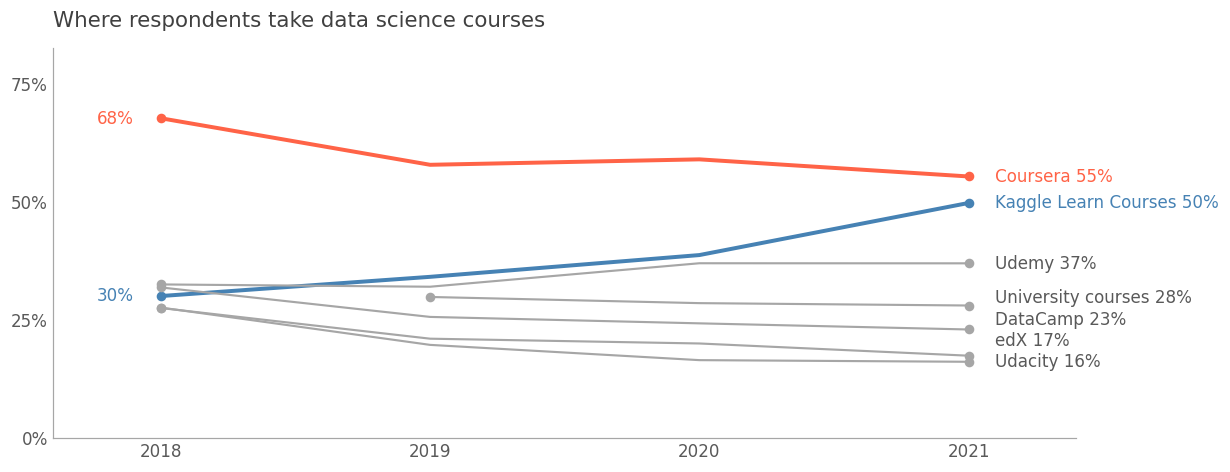

2026-11-02 14:51:42,339 - INFO - Figure saved to figures\08_learning_platforms.png


In [13]:
learning = multi_select_share('Q40').loc[['Coursera', 'Kaggle Learn Courses', 'Udemy', 'University courses', 'DataCamp', 'edX', 'Udacity']]

logger.info('=== Insight 8: learning is moving to free and practical platforms; Coursera, edX and Udacity are all down ===')
logger.info(f'Course platforms used (%):\n{learning.round(1)}')

fig, ax = plt.subplots(figsize=FIGSIZE)
line_chart(ax, learning, {'Kaggle Learn Courses': BLUE, 'Coursera': RED}, min_gap=4.5, title='Where respondents take data science courses', pct_ticks=[0, 25, 50, 75])

save_fig(fig, '08_learning_platforms')

In [14]:
headline = [
    ('1 Growth', 'Respondents', respondents, 2017),
    ('1 Geography', 'India share %', country_share.loc['India'], 2017),
    ('1 Geography', 'US share %', country_share.loc['United States'], 2017),
    ('2 Demographics', 'Age 18-24 share %', age_share.loc['18-24'], 2017),
    ('2 Demographics', 'Students share %', student_share, 2018),
    ('2 Demographics', 'Women share %', women_share, 2017),
    ('3 Languages', 'Python regular use %', languages.loc['Python'], 2018),
    ('3 Languages', 'R regular use %', languages.loc['R'], 2018),
    ('3 Languages', 'R recommended first %', recommended.loc['R'], 2017),
    ('4 Frameworks', 'PyTorch %', frameworks.loc['PyTorch'], 2018),
    ('4 Frameworks', 'TensorFlow %', frameworks.loc['TensorFlow'], 2018),
    ('5 Algorithms', 'Linear / Logistic Regression %', algorithms.loc['Linear / Logistic Regression'], 2019),
    ('5 Algorithms', 'Transformer Networks %', algorithms.loc['Transformer Networks'], 2019),
    ('6 Cloud', 'AWS among cloud users %', big_three.loc['AWS'], 2018),
    ('6 Cloud', 'Azure among cloud users %', big_three.loc['Azure'], 2018),
    ('7 Maturity', 'Employers with ML in production %', in_production, 2018),
    ('8 Learning', 'Coursera %', learning.loc['Coursera'], 2018),
    ('8 Learning', 'Kaggle Learn %', learning.loc['Kaggle Learn Courses'], 2018),
]
summary = pd.DataFrame([
    {'insight': insight, 'metric': metric, 'first': round(float(series[first_year]), 1), 'last': round(float(series[2021]), 1), 'first_year': first_year, 'last_year': 2021}
    for insight, metric, series, first_year in headline
])
summary['change'] = (summary['last'] - summary['first']).round(1)
summary.to_csv(FIG_DIR / 'insight_summary.csv', index=False)

logger.info(f'Headline numbers for the deck saved to {FIG_DIR / 'insight_summary.csv'}')
summary

2026-11-02 14:51:42,353 - INFO - Headline numbers for the deck saved to figures\insight_summary.csv


,insight,metric,first,last,first_year,last_year,change
0,1 Growth,Respondents,16716.0,25973.0,2017,2021,9257.0
1,1 Geography,India share %,16.3,28.6,2017,2021,12.3
2,1 Geography,US share %,25.3,10.2,2017,2021,-15.1
3,2 Demographics,Age 18-24 share %,22.6,36.9,2017,2021,14.3
4,2 Demographics,Students share %,22.0,26.2,2018,2021,4.2
5,2 Demographics,Women share %,16.6,18.8,2017,2021,2.2
6,3 Languages,Python regular use %,86.0,88.8,2018,2021,2.8
7,3 Languages,R regular use %,36.6,21.7,2018,2021,-14.9
8,3 Languages,R recommended first %,24.0,5.8,2017,2021,-18.2
9,4 Frameworks,PyTorch %,24.9,34.5,2018,2021,9.6
